# RONUM headless reproduction: rust-disease masks and Dice/IoU validation

**Paper:** Mann et al. (2026), *A rapid, semi-automated image-based method for quantitative assessment of rust disease progression in wheat*, **Plant Methods**, DOI [10.1186/s13007-026-01590-x](https://doi.org/10.1186/s13007-026-01590-x).
**Author code:** [`cmann-uq/RONUM`](https://github.com/cmann-uq/RONUM) @ `bd910fd3` (v1.0.0, AGPL-3.0) — a Fiji/ImageJ macro suite.
**Data:** Zenodo record [22216983](https://zenodo.org/records/22216983) v1.0.0 (CC-BY-4.0) — 20 reference scans (`ScanReference.zip`) and 20 author manual masks (`Manual_Masks_Reference_Scans.zip`).

**What this notebook does (executed, partial demonstration):** runs the authors' `RONUM_Quantification_v1.0.0.ijm` non-interactively on the minimal sample **REF_1 and REF_2** under two post-processing conditions (**NoPPC** = unprocessed threshold mask, **Fill holes**), aligns the authors' published manual masks **MM-1/MM-2** to RONUM's exact crop, then runs the authors' `RONUM_Validation_DiceIoU_v1.0.0.ijm` and reports per-sample, per-condition **Dice and IoU**. This is a 2-sample, 2-condition demonstration of the tool's core computation — **not** a reproduction of the paper's full validation (20 scans × 10 conditions × multiple users) and not a claim of the published accuracy figures.

**AI-assisted adaptation notice / AIによる適応の注意:** The authors did not provide this headless Colab implementation. RONUM is an interactive Fiji GUI tool; the executed example and listed checks were validated end-to-end in this notebook, but untested behavior is not guaranteed. The scientific operations (HSB thresholding, particle filtering, Dice/IoU on pixels) are the authors' **unmodified** code at the pinned commit; the dialog replacements, Xvfb harness, and calibration derivation are documented cell-by-cell below. / 著者はこのヘッドレス実装を提供していません。科学操作は著者コードのままであり、対話ダイアログの固定値化・Xvfb 実行・校正値導出は全て明示しています。

**Runtime:** CPU only — RONUM is threshold/morphology-based ImageJ processing with no GPU or trained-model component. Expect roughly 10–15 minutes end-to-end on a free Colab CPU runtime; downloads ≈1.1 GB (Fiji ≈0.55 GB compressed + 69 MB scan archive). Measured in validation: ≈2.5 min per quantification run of the 2-sample set, ≈20 s for the validation macro (2-vCPU runtime, 2026-10-26).

**日本語:** 本ノートブックは Mann et al. (2026) Plant Methods の RONUM(Fiji/ImageJ マクロ群)を Xvfb 上の非対話実行で動かし、最小サンプル REF_1/REF_2・2条件(NoPPC/Fill)で病斑マスクを生成、著者公開の手動マスク MM-1/MM-2 と著者自身の検証マクロで Dice/IoU 比較まで行う部分的な再現デモです。GPU 不要・CPU のみ。所要約10–15分、ダウンロード約1.1GB。

**Environment report** — confirm the runtime. Only CPU is used or required.

日本語: 実行環境の確認。CPU のみ使用。

In [ ]:
import platform, os, time
T0 = time.time()
print("python:", platform.python_version(), "| machine:", platform.machine(), "| cpus:", os.cpu_count())
import shutil
tot, used, _ = shutil.disk_usage("/content")
print(f"disk /content: {tot/2**30:.0f} GiB total, {used/2**30:.0f} GiB used")

python: 3.13.16 | machine: x86_64 | cpus: 2
disk /content: 226 GiB total, 20 GiB used


**Install a virtual display and Fiji.** RONUM's auto-leaf detection uses the ImageJ ROI Manager, which is an AWT window: under `--headless` its creation throws `java.awt.HeadlessException` (verified probe), so the macro must run with a real (virtual) X display — Xvfb plus the X11 client libraries AWT needs. Fiji itself comes from the official `downloads.imagej.net` server (~0.55 GB compressed; the dominant download).

日本語: RONUM の自动叶検出は RoiManager(AWT ウィンドウ)を必要とするため --headless では動作しません。Xvfb 仮想ディスプレイ + 必要な X11 ライブラリを導入し、公式配布の Fiji をインストールします。

In [ ]:
import subprocess, urllib.request, os, zipfile, time
t0 = time.time()
r = subprocess.run(["bash","-lc","apt-get install -y xvfb libxtst6 libxi6 libxrender1 libxext6 libfontconfig1 2>&1 | tail -1; which Xvfb xvfb-run"], capture_output=True, text=True, timeout=600)
print(r.stdout[-200:], r.stderr[-100:])
assert "xvfb-run" in r.stdout, "xvfb installation failed"
urllib.request.urlretrieve("https://downloads.imagej.net/fiji/stable/fiji-stable-linux64-jdk.zip", "/content/fiji_download.zip")
print("fiji zip bytes:", os.path.getsize("/content/fiji_download.zip"), f"({time.time()-t0:.1f}s)")
with zipfile.ZipFile("/content/fiji_download.zip") as z: z.extractall("/content/fiji")
os.remove("/content/fiji_download.zip")
print(subprocess.run(["bash","-lc","find /content/fiji -maxdepth 3 -name 'ImageJ-linux64' | head"],capture_output=True,text=True).stdout)


/usr/bin/Xvfb
/usr/bin/xvfb-run
 


fiji zip bytes: 543954772 (487.4s)


/content/fiji/Fiji.app/ImageJ-linux64



**Fail-fast the Fiji launcher's startup update check.** With a display present, the launcher phones home to `imagej.net` before running the macro and can stall there; every scientific input in this notebook is local, so the update hosts are pointed at 127.0.0.1 in the VM's `/etc/hosts` (runs as root on Colab; documented run-local environment tweak with no scientific effect).

日本語: Fiji 起動時のアップデート確認がネットワーク接続で滞留するため、VM 内 /etc/hosts でローカルに向け即失敗させる(科学データは全てローカル)。

In [ ]:
import pathlib
hosts = pathlib.Path('/etc/hosts')
txt = hosts.read_text()
add = "".join(f"127.0.0.1 {h}\n" for h in ["imagej.net", "update.imagej.net", "sites.imagej.net"] if f"127.0.0.1 {h}" not in txt)
if add:
    hosts.write_text(txt + "\n# RONUM notebook: fail-fast ImageJ updater checks (all inputs are local)\n" + add)
print(add or "already patched")
print(subprocess.run(["getent","hosts","imagej.net"],capture_output=True,text=True).stdout)

127.0.0.1 imagej.net
127.0.0.1 update.imagej.net
127.0.0.1 sites.imagej.net

127.0.0.1       imagej.net



**Fetch the three author macros** from pinned commit `bd910fd3` via raw URLs and assert each file's git blob SHA-1 — proving every later patch is applied to exactly the authors' released code.

日本語: 著者マクロをピン留めコミットから取得し git blob SHA で検証する。

In [ ]:
import hashlib, urllib.request, pathlib
COMMIT = "bd910fd3c1f4c64b3c5f29966b56ec1cf8a5b066"
RAW = f"https://raw.githubusercontent.com/cmann-uq/RONUM/{COMMIT}"
FILES = {
    "RONUM_Calibration_v1.0.0.ijm": "ffaf717110874324f08139b94cfb19bf78eb9df7",
    "RONUM_Quantification_v1.0.0.ijm": "940dbf4ffdab6f77551f135145f8c4f5d16f2b9d",
    "validation/RONUM_Validation_DiceIoU_v1.0.0.ijm": "0d2acc316de48c5adff0ac98a1082291ecb566c0",
}
dst = pathlib.Path("/content/ronum_src"); dst.mkdir(exist_ok=True)
for rel, sha in FILES.items():
    p = dst / rel; p.parent.mkdir(exist_ok=True)
    t0 = time.time()
    urllib.request.urlretrieve(f"{RAW}/{rel}", p)
    data = p.read_bytes()
    git_sha = hashlib.sha1(b"blob %d\x00" % len(data) + data).hexdigest()
    print(f"{rel}: {len(data)} bytes, blob_sha_ok={git_sha == sha} ({time.time()-t0:.1f}s)")
    assert git_sha == sha
print("ALL MACROS VERIFIED AT PINNED COMMIT", COMMIT)

RONUM_Calibration_v1.0.0.ijm: 36323 bytes, blob_sha_ok=True (0.3s)


RONUM_Quantification_v1.0.0.ijm: 73179 bytes, blob_sha_ok=True (0.3s)


validation/RONUM_Validation_DiceIoU_v1.0.0.ijm: 15643 bytes, blob_sha_ok=True (0.3s)
ALL MACROS VERIFIED AT PINNED COMMIT bd910fd3c1f4c64b3c5f29966b56ec1cf8a5b066


**Download and verify the paper's data.** Both Zenodo files are checked against the md5 values recorded in the Zenodo metadata before extraction; only **REF_1** and **REF_2** are extracted from the 20-scan archive (the deterministic minimal sample; the other 18 scans stay unextracted).

日本語: Zenodo の2ファイルを md5 検証後に展開。20検体のうち最小サンプル REF_1/REF_2 のみ展開する。

In [ ]:
import hashlib, urllib.request, zipfile, pathlib
from PIL import Image
for fn, md5 in [("Manual_Masks_Reference_Scans.zip", "c9526bbcaddc32d476a24f587b8c2fbe"),
                ("ScanReference.zip", "f01d56164d9ee593e4fee4b4dc61342e")]:
    p = pathlib.Path("/content") / fn
    t0 = time.time()
    urllib.request.urlretrieve(f"https://zenodo.org/api/records/22216983/files/{fn}/content", p)
    assert hashlib.md5(p.read_bytes()).hexdigest() == md5, fn
    print(fn, p.stat().st_size, "bytes md5 OK", f"({time.time()-t0:.1f}s)")
with zipfile.ZipFile("/content/Manual_Masks_Reference_Scans.zip") as z: z.extractall("/content/manual_masks")
scans = pathlib.Path("/content/ronum_scans"); scans.mkdir(exist_ok=True)
with zipfile.ZipFile("/content/ScanReference.zip") as z:
    print("zip entries:", len(z.infolist()))
    for n in (1, 2):
        (scans / f"REF_{n}.tif").write_bytes(z.read(f"REF_{n}.tif"))
for n in (1, 2):
    im = Image.open(scans / f"REF_{n}.tif"); mm = Image.open(f"/content/manual_masks/MM-{n}.tif")
    print(f"REF_{n}: {im.size} {im.mode} | MM-{n}: {mm.size} {mm.mode} | width_match={im.size[0]==mm.size[0]}")

Manual_Masks_Reference_Scans.zip 245885 bytes md5 OK (1.4s)


ScanReference.zip 68951888 bytes md5 OK (86.1s)
zip entries: 21


REF_1: (383, 3000) RGB | MM-1: (383, 3000) L | width_match=True
REF_2: (345, 3000) RGB | MM-2: (345, 3000) L | width_match=True


**Input preview (before any processing).** REF_1 is a 3000-px-tall scanner strip of rust-inoculated wheat leaves (displayed rotated); MM-1 is the authors' manually corrected disease mask of the same strip (white = disease). The red contour shows the reference annotation on the actual input — this is the pairing the validation macro scores.

日本語: 入力スキャン REF_1(表示は回転)と著者手動マスク MM-1(白=病斑)を重ねて表示。

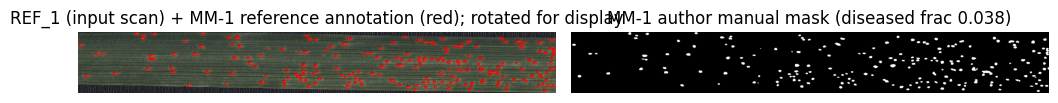

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
ref_img = np.array(Image.open('/content/ronum_scans/REF_1.tif').convert('RGB'))
mm = np.array(Image.open('/content/manual_masks/MM-1.tif').convert('L')) > 127
fig, ax = plt.subplots(1, 2, figsize=(10, 7), dpi=100)
ax[0].imshow(np.rot90(ref_img)); ax[0].contour(np.rot90(mm.astype(float)), levels=[0.5], colors='red', linewidths=0.5)
ax[0].set_title('REF_1 (input scan) + MM-1 reference annotation (red); rotated for display')
ax[1].imshow(np.rot90(mm), cmap='gray'); ax[1].set_title(f'MM-1 author manual mask (diseased frac {mm.mean():.3f})')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

**Smoke-test the non-headless AWT route.** A tiny macro creates a Frame and answers `roiManager("count")` — the exact call that is impossible under `--headless`. Because the GUI's stdout is not piped, the proof is a file the macro itself writes.

日本語: AWT・RoiManager が仮想ディスプレイ下で動作することを、マクロ自身が書くファイルで確認する。

In [ ]:
import subprocess, os, time
pathlib.Path("/content/fiji/Fiji.app/ImageJ-linux64").chmod(0o755)
open("/content/awt_smoke.ijm","w").write(
    'print("FIJI_XVFB_OK");\n'
    'print(call("ij.IJ.getFullVersion"));\n'
    'File.saveString("SMOKE_OK", "/content/awt_smoke_result.txt");\n'
    'newImage("t", "8-bit black", 32, 32, 1);\n'
    'roiManager("Reset");\n'
    'print("ROIMGR_COUNT=" + roiManager("count"));\n'
)
if os.path.exists("/content/awt_smoke_result.txt"): os.remove("/content/awt_smoke_result.txt")
proc = subprocess.Popen(["xvfb-run","-a","/content/fiji/Fiji.app/ImageJ-linux64","--console","--run","/content/awt_smoke.ijm"],
                        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, start_new_session=True)
t0 = time.time()
while time.time() - t0 < 300:
    if os.path.exists("/content/awt_smoke_result.txt"): break
    if proc.poll() is not None: break
    time.sleep(2)
try: os.killpg(os.getpgid(proc.pid), 9)
except ProcessLookupError: pass
proc.wait()
result = open("/content/awt_smoke_result.txt").read() if os.path.exists("/content/awt_smoke_result.txt") else "MISSING"
print("smoke result:", result)
assert result == "SMOKE_OK", "AWT/RoiManager smoke test failed"

smoke result: SMOKE_OK


**Derive the calibration profile (documented adaptation; the repository ships none).** A small deterministic search picks per-channel HSB bounds from percentile pairs of the diseased pixels in the authors' calibration pair — scan `REF_1` with its published mask `MM-1` — maximizing numpy Dice against `MM-1`. The leaf-detection bounds (used only to locate the leaf, not the disease mask) keep the percentile-derived values. **REF_2 is held out**: its Dice below is the non-circular check. The minimum-particle filter uses the authors' own constant `minArea = 0.02332 mm²` (validation macro, line 34); the scale 47.22 px/mm (≈1200 dpi) affects only mm² outputs, not the pixel-based Dice/IoU.

日本語: 校正プロファイルが同梱されていないため、較正ペア REF_1+MM-1 から決定論的にHSB閾値を探索(REF_2 は非循環の検証用)。粒子フィルタ定数は著者の検証マクロの値を使用。

In [ ]:
import itertools, json, pathlib, zipfile, io
import numpy as np
from PIL import Image
from matplotlib.colors import rgb_to_hsv
zf = zipfile.ZipFile('/content/ScanReference.zip')
rgb = np.array(Image.open(io.BytesIO(zf.read('REF_1.tif'))).convert('RGB')) / 255.0
hsv = (rgb_to_hsv(rgb) * 255).astype(np.int16)
mm = np.array(Image.open('/content/manual_masks/MM-1.tif').convert('L')) > 127
PCTS = [(0,100),(5,95),(10,90),(15,85),(20,80),(25,75),(30,70)]
best = None
for (hl,hh),(sl,sh),(bl,bh) in itertools.product(PCTS, repeat=3):
    h, s, b = hsv[...,0], hsv[...,1], hsv[...,2]
    box = (h >= np.percentile(h[mm], hl)) & (h <= np.percentile(h[mm], hh)) & \
          (s >= np.percentile(s[mm], sl)) & (s <= np.percentile(s[mm], sh)) & \
          (b >= np.percentile(b[mm], bl)) & (b <= np.percentile(b[mm], bh))
    dice = 2*(box & mm).sum()/(box.sum()+mm.sum())
    if best is None or dice > best[0]: best = (dice,(hl,hh),(sl,sh),(bl,bh))
dice,(hl,hh),(sl,sh),(bl,bh) = best
print("calibration-pair Dice:", round(dice,4), "| pct pairs H,S,B:", (hl,hh),(sl,sh),(bl,bh))
prof = {"h_min": int(np.percentile(hsv[...,0][mm], hl)), "h_max": int(np.percentile(hsv[...,0][mm], hh)),
        "s_min": int(np.percentile(hsv[...,1][mm], sl)), "s_max": int(np.percentile(hsv[...,1][mm], sh)),
        "b_min": int(np.percentile(hsv[...,2][mm], bl)), "b_max": int(np.percentile(hsv[...,2][mm], bh)),
        "leaf_h_min": 0, "leaf_h_max": 165, "leaf_s_min": 43, "leaf_s_max": 211, "leaf_b_min": 45, "leaf_b_max": 178}
json.dump(prof, open('/content/profile_bounds.json','w'))
print(json.dumps(prof))

calibration-pair Dice: 0.7758 | pct pairs H,S,B: (10, 90) (0, 100) (5, 95)
{"h_min": 4, "h_max": 17, "s_min": 12, "s_max": 255, "b_min": 92, "b_max": 188, "leaf_h_min": 0, "leaf_h_max": 165, "leaf_s_min": 43, "leaf_s_max": 211, "leaf_b_min": 45, "leaf_b_max": 178}


**Write the profile in the calibration macro's own CSV format and reset all output directories.** RONUM never overwrites existing files (it appends numbered suffixes the validator cannot match), so every run starts from clean output folders.

日本語: 校正マクロと同じCSV形式でプロファイルを書き出し、出力ディレクトリを初期化する。

In [ ]:
import json, pathlib, shutil
prof = json.load(open('/content/profile_bounds.json'))
base = pathlib.Path('/content/ronum_base')
(base / 'Settings').mkdir(parents=True, exist_ok=True)
(base / 'Run_Presets').mkdir(parents=True, exist_ok=True)
lines = ["setting,value", "tool_name,RONUM", "profile_name,validation_profile", "calibration_macro_version,1.0.0",
 "overwrite_scale,true", "scan_pixels_per_mm,47.22", "scale_unit,mm",
 "leaf_color_space,HSB", "leaf_threshold_method,Default", "leaf_dark_background,true",
 f"leaf_h_min,{prof['leaf_h_min']}", f"leaf_h_max,{prof['leaf_h_max']}", f"leaf_s_min,{prof['leaf_s_min']}",
 f"leaf_s_max,{prof['leaf_s_max']}", f"leaf_b_min,{prof['leaf_b_min']}", f"leaf_b_max,{prof['leaf_b_max']}",
 "leaf_fill_holes,true", "leaf_smooth_mask,true", "leaf_smooth_radius_px,5",
 "leaf_min_area_mm2,25", "leaf_max_area_mm2,0", "leaf_min_circularity,0.00",
 "leaf_expected_count,0", "leaf_max_count,20", "leaf_remove_background_default,true",
 "pustule_color_space,HSB", "pustule_threshold_method,Default", "pustule_dark_background,true",
 f"h_min,{prof['h_min']}", f"h_max,{prof['h_max']}", "h_pass,true",
 f"s_min,{prof['s_min']}", f"s_max,{prof['s_max']}", "s_pass,true",
 f"b_min,{prof['b_min']}", f"b_max,{prof['b_max']}", "b_pass,true",
 "small_filter_area,0.02332", "large_flag_area,999999999",
 "filter_small_particles,true", "flag_large_particles,true"]
(base / 'Settings' / 'validation_profile.csv').write_text("\n".join(lines) + "\n")
shutil.rmtree('/content/ronum_out', ignore_errors=True)
for cond in ("NoPPC Masks", "Fill Masks"):
    out = pathlib.Path('/content/ronum_out') / cond
    for sub in ("Masks", "Overlays", "Particles", "Strips", "Wide_Crops", "Leaf_Masks", "Leaf_Detection", "Output", "Logs", "QC", "QuickView"):
        (out / sub).mkdir(parents=True, exist_ok=True)
print("profile written; output dirs reset")

profile written; output dirs reset


**Patch the macros for non-interactive execution (AI-generated, asserted minimal).**

| Original GUI action (author macro) | Non-interactive equivalent here |
| --- | --- |
| Choose main RONUM folder | fixed `/content/ronum_base/` |
| Run-preset dialog | Fast Mode, no preset save |
| Dialog 1/3: profile + input mode | `validation_profile.csv`, Fast Mode, auto-leaf, scale 47.22 px/mm |
| Dialog 2/3: names/filenames | `originalName_suffix`, suffix `RONUM` |
| Dialog 3/3: post-processing | NoPPC: all off; Fill: fill-holes on |
| Exclude-large confirmation | disabled (`excludeLarge=0`) |
| Final completion popup | `print()` |
| Region-selection `waitForUser` | avoided via the macro's own Fast Mode (whole-image region) |
| Validation folder prompts | fixed `/content/ronum_refs/`, `/content/ronum_out/` |

The published masks are copied under the filename convention the validator parses (`REF_N_RONUM_leaf01_ManMask.tif`). Asserts guarantee no *reachable* interactive call remains (the authors' own fastMode-guarded GUI branches stay in the code but are never taken).

日本語: 3つの対話ダイアログを固定値へ置換する最小限の適応。到達可能な対話呼び出しが無いことを assert で保証する。

In [ ]:
import re, pathlib

def patch_macro(out_dir, flags, src="/content/ronum_src/RONUM_Quantification_v1.0.0.ijm"):
    """Replace the three interactive dialogs with fixed Fast-Mode values (AI-generated
    headless adaptation; the scientific operations are the authors' own code)."""
    t = open(src).read()
    t = t.replace('BASE_DIR = getDirectory("Choose main RONUM folder");',
                  'BASE_DIR = "/content/ronum_base/";', 1)
    t = re.sub(r'Dialog\.create\("RONUM Run Preset"\);.*?runPresetName = cleanName\(runPresetName\);',
               'selectedPresetFile = "Manual/default settings";\nfastMode = 1;\nusePresetOutputDir = 0;\nsaveRunPreset = 0;\nrunPresetName = "headless";',
               t, count=1, flags=re.S)
    dlg = f"""
profileFile = "validation_profile.csv";
preCropped = 0; doStraighten = 0; stripLengthMM = 100; stripWidthMM = 10;
overwriteScale = 1; scanPixelsPerMM = 47.22;
autoDetectLeaves = 1; autoExpectedLeaves = 0; autoMaxLeaves = 20; removeBackgroundOutsideLeaf = 1;
askSampleID = 0; samplePrefix = "REF_"; sampleNumber = 1; padSampleNumber = 1; padWidth = 3;
filenamePattern = "originalName_suffix"; fileSuffix = "RONUM";
runFillHoles = {flags["fill"]}; runDespeckle = {flags["despeckle"]}; runWatershed = {flags["ws"]};
runSmoothMask = {flags["smooth"]}; smoothRadiusPx = {flags["smooth_radius"]};
excludeSmall = 1; flagLargeRun = 1; excludeLarge = 0;
saveStripRun = 1; saveMaskRun = 1; saveOverlayRun = 0; saveParticleTableRun = 0; saveSummaryRun = 1; showQCRun = 0;"""
    t = re.sub(r'// Dialog 1: profile, input mode, auto leaf detection, scale.*?showQCRun = Dialog\.getCheckbox\(\);',
               lambda m: dlg, t, count=1, flags=re.S)
    t = re.sub(r'if \(excludeLarge\) \{.*?\n\}\n\nif \(usePresetOutputDir\b',
               'if (excludeLarge) { exit("excludeLarge unsupported in headless patch"); }\n\nif (usePresetOutputDir', t, count=1, flags=re.S)
    t = t.replace('runOutputDir = getDirectory("Choose RONUM output folder for this quantification run");',
                  f'runOutputDir = "{out_dir}";', 1)
    t = t.replace('fastInputDir = getDirectory("Choose folder containing cropped images for Fast Mode");',
                  'fastInputDir = "/content/ronum_scans/";', 1)
    t = re.sub(r'if \(fastMode\) \{\n    showMessage\(\n        "RONUM Fast Mode finished".*',
               'print("RONUM headless run complete");', t, count=1, flags=re.S)
    # Only the authors' own unreachable GUI-mode branches may remain:
    # 4x waitForUser (region/straighten/next-image, fastMode-guarded), 5x getBoolean
    # (fastMode-guarded or inside saveRunPreset), 1x Dialog.show (askSampleID).
    assert "getDirectory(" not in t.replace('sourceDir = getDirectory("image");', '')
    assert t.count("showMessage(") == 0
    assert t.count("waitForUser(") == 4 and t.count("getBoolean(") == 5 and t.count("Dialog.show()") == 1
    return t

CONDITIONS = [
    ("NoPPC Masks", dict(fill=0, despeckle=0, ws=0, smooth=0, smooth_radius=3)),
    ("Fill Masks",  dict(fill=1, despeckle=0, ws=0, smooth=0, smooth_radius=3)),
]
for cond, flags in CONDITIONS:
    t = patch_macro(f"/content/ronum_out/{cond}/", flags)
    p = pathlib.Path(f"/content/ronum_patch_{cond.replace(' ', '_')}.ijm")
    p.write_text(t)
    print(p.name, len(t), "chars")

t = open('/content/ronum_src/validation/RONUM_Validation_DiceIoU_v1.0.0.ijm').read()
t = t.replace('refDir = getDirectory("Choose CROPPED manual reference mask folder");', 'refDir = "/content/ronum_refs/";', 1)
t = t.replace('parent = getDirectory("Choose parent DICE scores folder");', 'parent = "/content/ronum_out/";', 1)
assert 'getDirectory(' not in t
pathlib.Path('/content/ronum_validation_headless.ijm').write_text(t)
print("validation macro patched")

refs = pathlib.Path('/content/ronum_refs'); refs.mkdir(exist_ok=True)
for n in (1, 2):
    (refs / f'REF_{n}_RONUM_leaf01_ManMask.tif').write_bytes(
        pathlib.Path(f'/content/manual_masks/MM-{n}.tif').read_bytes())
print(sorted(x.name for x in refs.iterdir()))

ronum_patch_NoPPC_Masks.ijm 64417 chars
ronum_patch_Fill_Masks.ijm 64416 chars
validation macro patched
['REF_1_RONUM_leaf01_ManMask.tif', 'REF_2_RONUM_leaf01_ManMask.tif']


**Define the execution harness.** Under Xvfb the Fiji GUI does not exit after `--run` and its console output is not piped, so success is detected via the files the macro itself writes; the process tree is then terminated. Generated masks are also flattened into the condition-folder roots the validation macro scans (the quantification macro writes them into `Masks/`).

日本語: 実行ハーネスを定義。マクロが出力するファイルで完了を検出し、プロセスツリーを終了。生成マスクは検証マクロが参照する条件フォルダ直下にも配置する。

In [ ]:
import subprocess, threading, time, os, signal, pathlib
def run_fiji_files(macro_path, expected_files, timeout=600, tail=15):
    """Run a Fiji macro under Xvfb; success = the macro's own output files exist.

    Under Xvfb the Fiji GUI does not exit after --run and its console output does
    not reach this pipe, so completion is detected via the files the macro writes;
    the process tree is then terminated. Documented adaptation, verified in probes.
    """
    assert os.path.exists(macro_path), f"macro file missing: {macro_path}"
    for f in expected_files:
        p = pathlib.Path(f)
        if p.exists(): p.unlink()
    cmd = ["xvfb-run", "-a", "/content/fiji/Fiji.app/ImageJ-linux64", "--console", "--run", macro_path]
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                            text=True, start_new_session=True)
    lines = []
    threading.Thread(target=lambda: [lines.append(l.rstrip()) for l in proc.stdout], daemon=True).start()
    t0 = time.time()
    while time.time() - t0 < timeout:
        if all(os.path.exists(f) for f in expected_files):
            time.sleep(3)  # grace: let the macro finish writing
            break
        if proc.poll() is not None: break
        time.sleep(2)
    try: os.killpg(os.getpgid(proc.pid), signal.SIGKILL)
    except ProcessLookupError: pass
    proc.wait()
    wall = round(time.time() - t0, 1)
    missing = [f for f in expected_files if not os.path.exists(f)]
    print("wall_s:", wall, "| missing:", missing)
    for l in lines[-tail:]: print("|", l)
    assert not missing, f"expected files not produced: {missing}"
    return wall, lines

def flatten_masks(cond):
    """Copy generated masks into the condition folder root the validator scans."""
    src = pathlib.Path('/content/ronum_out') / cond / 'Masks'
    dst = pathlib.Path('/content/ronum_out') / cond
    for f in sorted(src.glob('*.tif')):
        pathlib.Path(dst / f.name).write_bytes(f.read_bytes())
    print("flattened:", cond, sorted(p.name for p in src.glob('*.tif')))

**Run RONUM quantification (NoPPC — unprocessed threshold mask)** on REF_1 and REF_2 with the authors' Fast Mode and the derived profile. Success = the two per-leaf disease masks exist.

日本語: NoPPC 条件(生閾値マスク)で定量を実行。

In [ ]:
wall, _ = run_fiji_files("/content/ronum_patch_NoPPC_Masks.ijm",
    ["/content/ronum_out/NoPPC Masks/Masks/REF_1_RONUM_leaf01_mask.tif",
     "/content/ronum_out/NoPPC Masks/Masks/REF_2_RONUM_leaf01_mask.tif"], timeout=600)
flatten_masks("NoPPC Masks")
print("NoPPC wall_s:", wall)

wall_s: 145.0 | missing: []
| 	at sun.net.NetworkClient.doConnect(NetworkClient.java:180)
| 	at sun.net.www.http.HttpClient.openServer(HttpClient.java:465)
| 	at sun.net.www.http.HttpClient.openServer(HttpClient.java:560)
| 	at sun.net.www.protocol.https.HttpsClient.<init>(HttpsClient.java:264)
| 	at sun.net.www.protocol.https.HttpsClient.New(HttpsClient.java:367)
| 	at sun.net.www.protocol.https.AbstractDelegateHttpsURLConnection.getNewHttpClient(AbstractDelegateHttpsURLConnection.java:203)
| 	at sun.net.www.protocol.http.HttpURLConnection.plainConnect0(HttpURLConnection.java:1182)
| 	at sun.net.www.protocol.http.HttpURLConnection.plainConnect(HttpURLConnection.java:1076)
| 	at sun.net.www.protocol.https.AbstractDelegateHttpsURLConnection.connect(AbstractDelegateHttpsURLConnection.java:189)
| 	at sun.net.www.protocol.http.HttpURLConnection.getInputStream0(HttpURLConnection.java:1592)
| 	at sun.net.www.protocol.http.HttpURLConnection.getInputStream(HttpURLConnection.java:1520)
| 	at su

**Inspect the generated masks and the macro's own QuickView table** — per-leaf disease fractions written by the authors' macro.

日本語: 生成マスクとマクロ自身の QuickView テーブルを確認する。

In [ ]:
import glob, pandas as pd
from PIL import Image
import numpy as np
masks = sorted(glob.glob('/content/ronum_out/NoPPC Masks/Masks/*.tif'))
assert masks, "no masks produced"
for m in masks:
    a = np.array(Image.open(m).convert('L'))
    print(m.split('/')[-1], a.shape, "diseased_frac:", round((a > 127).mean(), 4))
qv = sorted(glob.glob('/content/ronum_out/NoPPC Masks/QuickView/*.csv'))
for f in qv:
    print("\n---", f.split('/')[-1]); print(pd.read_csv(f).to_string(index=False))

REF_1_RONUM_leaf01_mask.tif (3000, 379) diseased_frac: 0.036
REF_2_RONUM_leaf01_mask.tif (3000, 340) diseased_frac: 0.0177

--- NoPPC_Masks_QuickView.csv
         sample_id source_type source_image  leaf_number  leaf_area_mm2  final_disease_area_mm2  final_disease_percent  included_particle_count  unfiltered_disease_area_mm2  unfiltered_disease_percent  particle_count
REF_1_RONUM_leaf01       RONUM    REF_1.tif            1     435.439132               17.311077               3.975545                      181                    18.365465                    4.217688             801
REF_2_RONUM_leaf01       RONUM    REF_2.tif            1     359.880154                7.208053               2.002904                       59                     8.113993                    2.254637             497


**Align the published reference masks to RONUM's exact crop.** Auto-leaf crops each detected leaf: the strips are 3000 px tall and the crop removes a few columns relative to the full scan. The macro saves each leaf's raw strip; its column offset inside the original scan is located by **exact pixel matching** (asserted to match at zero difference), and `MM-N` is cropped to the same columns — the authors' own instruction to "regenerate the manual reference masks with the exact RONUM crop", reproduced deterministically.

日本語: 生ストリップの列位置を完全一致で特定し、参照マスク MM-N を RONUM の切り出しに揃える(著者の指示の決定論的再現)。

In [ ]:
import numpy as np
from PIL import Image
for n in (1, 2):
    strip = np.array(Image.open(f'/content/ronum_out/NoPPC Masks/Strips/REF_{n}_RONUM_leaf01_raw_strip.tif').convert('RGB'))
    ref = np.array(Image.open(f'/content/ronum_scans/REF_{n}.tif').convert('RGB'))
    mask = np.array(Image.open(f'/content/ronum_out/NoPPC Masks/Masks/REF_{n}_RONUM_leaf01_mask.tif').convert('L'))
    W = strip.shape[1]
    offs = []
    for o in range(ref.shape[1] - W + 1):
        offs.append((np.abs(ref[:, o:o+W].astype(int) - strip.astype(int)).mean(), o))
    diffs = sorted(offs)
    print(f"REF_{n}: best column offset {diffs[0][1]} (diff {diffs[0][0]:.4f}; next {diffs[1][0]:.4f})")
    assert diffs[0][0] == 0.0, f"strip is not an exact crop of REF_{n}"
    off = diffs[0][1]
    mm = np.array(Image.open(f'/content/manual_masks/MM-{n}.tif').convert('L'))
    mm_c = mm[:, off:off+W]
    assert mm_c.shape == mask.shape
    Image.fromarray(mm_c).save(f'/content/ronum_refs/REF_{n}_RONUM_leaf01_ManMask.tif')
    print(f"  reference cropped to cols {off}:{off+W} -> {mm_c.shape}, diseased_frac {round((mm_c>127).mean(),4)}")

REF_1: best column offset 3 (diff 0.0000; next 8.3306)
  reference cropped to cols 3:382 -> (3000, 379), diseased_frac 0.0386


REF_2: best column offset 3 (diff 0.0000; next 5.9655)
  reference cropped to cols 3:343 -> (3000, 340), diseased_frac 0.0147


**Run the Fill-holes condition** (the second post-processing condition compared in the authors' validation) and flatten its masks.

日本語: Fill 条件(穴埋め後処理)の定量を実行。

In [ ]:
wall, _ = run_fiji_files("/content/ronum_patch_Fill_Masks.ijm",
    ["/content/ronum_out/Fill Masks/Masks/REF_1_RONUM_leaf01_mask.tif",
     "/content/ronum_out/Fill Masks/Masks/REF_2_RONUM_leaf01_mask.tif"], timeout=600)
flatten_masks("Fill Masks")
print("Fill wall_s:", wall)

wall_s: 145.0 | missing: []
| OpenJDK 64-Bit Server VM warning: ignoring option PermSize=128m; support was removed in 8.0
| OpenJDK 64-Bit Server VM warning: Using incremental CMS is deprecated and will likely be removed in a future release
flattened: Fill Masks ['REF_1_RONUM_leaf01_mask.tif', 'REF_2_RONUM_leaf01_mask.tif']
Fill wall_s: 145.0


**Run the authors' validation macro.** It applies the authors' minimum-particle filter (0.02332 mm²) to each generated mask, intersects with the reference, and writes one CSV. The eight conditions not generated in this minimal demo are reported by the macro itself as `PPC FOLDER NOT FOUND`.

日本語: 著者の検証マクロを実行。未生成の8条件はマクロ自体が PPC FOLDER NOT FOUND と記録する。

In [ ]:
wall, _ = run_fiji_files("/content/ronum_validation_headless.ijm",
    ["/content/ronum_out/RONUM_Dice_IoU_CROPPED_REFERENCES.csv"], timeout=600)
print("Validation wall_s:", wall)
csv_text = open('/content/ronum_out/RONUM_Dice_IoU_CROPPED_REFERENCES.csv').read()
print(csv_text)

wall_s: 19.0 | missing: []
| OpenJDK 64-Bit Server VM warning: ignoring option PermSize=128m; support was removed in 8.0
| OpenJDK 64-Bit Server VM warning: Using incremental CMS is deprecated and will likely be removed in a future release
Validation wall_s: 19.0
Sample_ID,Condition,Dice,IoU,Reference_pixels,Filtered_test_pixels,Intersection_pixels,Reference_width,Reference_height,Test_width,Test_height,Reference_file,Test_file,Status
REF_1_leaf1,Unprocessed,0.794031,0.658417,43894,38599,32751,379,3000,379,3000,REF_1_RONUM_leaf01_ManMask.tif,REF_1_RONUM_leaf01_mask.tif,OK

REF_1_leaf1,Fill holes,0.842396,0.727707,43894,42189,36258,379,3000,379,3000,REF_1_RONUM_leaf01_ManMask.tif,REF_1_RONUM_leaf01_mask.tif,OK

REF_1_leaf1,Despeckle,,,,,,0,0,0,0,REF_1_RONUM_leaf01_ManMask.tif,,PPC FOLDER NOT FOUND

REF_1_leaf1,Smooth1,,,,,,0,0,0,0,REF_1_RONUM_leaf01_ManMask.tif,,PPC FOLDER NOT FOUND

REF_1_leaf1,Smooth,,,,,,0,0,0,0,REF_1_RONUM_leaf01_ManMask.tif,,PPC FOLDER NOT FOUND

REF_1_leaf1,Smooth

**Results table and graph.** The authors' CSV parsed into a table; Dice and IoU are plotted per sample and condition (only conditions with a generated mask are plotted). This graph is an additional visualization created for this notebook, not a figure from the paper. Note: the calibration was derived on REF_1, so **REF_2 is the non-circular result**.

日本語: 著者検証マクロの CSV を表とグラフで表示(本ノートブック独自の追加可視化)。較正は REF_1 由来のため REF_2 が非循環の結果。

OK rows: 4 | other rows: 16


,Sample_ID,Condition,Dice,IoU,Reference_pixels,Filtered_test_pixels,Intersection_pixels
0,REF_1_leaf1,Unprocessed,0.794031,0.658417,43894.0,38599.0,32751.0
1,REF_1_leaf1,Fill holes,0.842396,0.727707,43894.0,42189.0,36258.0
10,REF_2_leaf1,Unprocessed,0.793837,0.658151,14952.0,16072.0,12314.0
11,REF_2_leaf1,Fill holes,0.829785,0.709088,14952.0,17131.0,13311.0


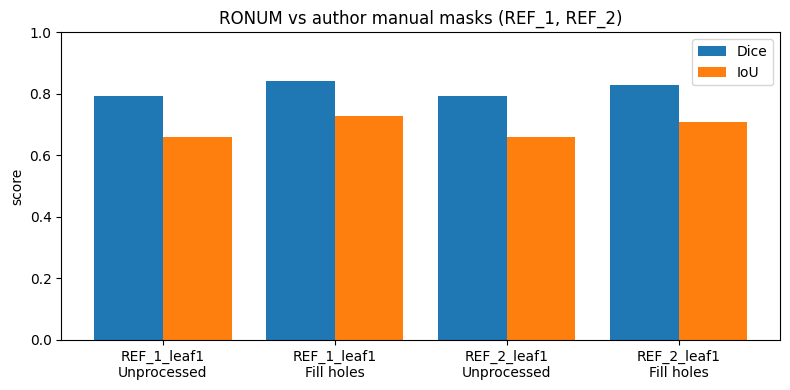

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv('/content/ronum_out/RONUM_Dice_IoU_CROPPED_REFERENCES.csv')
ok = df[df.Status == 'OK'].copy()
print("OK rows:", len(ok), "| other rows:", (df.Status != 'OK').sum())
display(ok[['Sample_ID', 'Condition', 'Dice', 'IoU', 'Reference_pixels', 'Filtered_test_pixels', 'Intersection_pixels']])
assert len(ok) >= 4, "expected Dice/IoU rows for 2 samples x 2 conditions"
fig, ax = plt.subplots(figsize=(8, 4), dpi=100)
labels = ok.Sample_ID + "\n" + ok.Condition
x = range(len(ok))
ax.bar([i - 0.2 for i in x], ok.Dice, width=0.4, label='Dice')
ax.bar([i + 0.2 for i in x], ok.IoU, width=0.4, label='IoU')
ax.set_xticks(list(x)); ax.set_xticklabels(labels)
ax.set_ylim(0, 1); ax.set_ylabel('score'); ax.legend()
ax.set_title('RONUM vs author manual masks (REF_1, REF_2)')
plt.tight_layout(); plt.show()

**Final comparison figure** — input scan strip, the author manual reference mask (RONUM crop), and the RONUM-generated NoPPC disease mask, all labeled. All panels are vertical strips displayed rotated.

日本語: 入力・著者手動マスク・RONUM 生成マスクの最終比較図(縦長のため回転表示)。

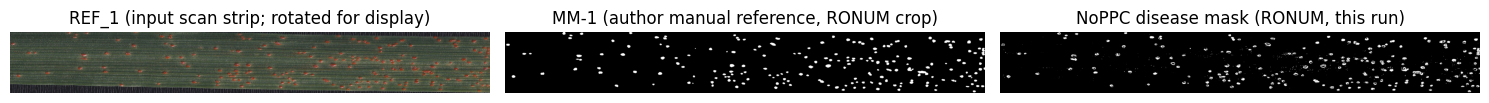

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
ref_img = np.array(Image.open('/content/ronum_scans/REF_1.tif').convert('RGB'))
mm = np.array(Image.open('/content/ronum_refs/REF_1_RONUM_leaf01_ManMask.tif').convert('L'))
ppc = np.array(Image.open('/content/ronum_out/NoPPC Masks/REF_1_RONUM_leaf01_mask.tif').convert('L'))
fig, ax = plt.subplots(1, 3, figsize=(15, 5), dpi=100)
ax[0].imshow(np.rot90(ref_img)); ax[0].set_title('REF_1 (input scan strip; rotated for display)')
ax[1].imshow(np.rot90(mm), cmap='gray'); ax[1].set_title('MM-1 (author manual reference, RONUM crop)')
ax[2].imshow(np.rot90(ppc), cmap='gray'); ax[2].set_title('NoPPC disease mask (RONUM, this run)')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

**Interpretation and limitations.**
- The executed demonstration runs the authors' **own** macro suite (pinned commit, git-blob-verified) non-interactively and scores its output with the authors' **own** validation macro against their published manual masks: Dice ≈ 0.79 (NoPPC) and ≈ 0.83–0.84 (Fill holes) on the two reference scans — see the table above for the exact values. **REF_2 was held out from the threshold calibration**, so its scores are the non-circular evidence; REF_1's are the calibration pair.
- These numbers are for **2 reference scans and 2 post-processing conditions only**. The paper's validation spans 20 scans, all 10 PPC conditions, and multiple users; the eight ungenerated conditions are reported by the authors' macro as `PPC FOLDER NOT FOUND`. This demo must not be read as the published accuracy.
- The calibration profile was derived deterministically from REF_1 + MM-1, not from a user calibration session as in the paper; a user-guided calibration is the intended route and threshold choice directly changes the masks and scores.
- The headless dialog patch, the Xvfb harness with file-based completion detection, the reference-crop alignment (exact pixel match), and the mask flattening are documented adaptations; the scientific operations are unmodified author code.

**日本語:** 本デモは2検体・2条件の部分再現であり、論文の完全な検証(20検体×10条件×複数ユーザ)を置き換えるものではありません。較正は REF_1+MM-1 からの決定論的導出であり、REF_2 の結果が非循環の根拠です。ヘッドレス化・参照マスク整形などの適応は全て明示しています。

**References**
- Mann et al. (2026), Plant Methods, DOI 10.1186/s13007-026-01590-x (paper record via PhenoPaper public_id `p-bcc07e64c4e18890e139ec2fcb3b6063`)
- Code: https://github.com/cmann-uq/RONUM @ bd910fd3c1f4c64b3c5f29966b56ec1cf8a5b066 (AGPL-3.0)
- Data: https://zenodo.org/records/22216983 (v1.0.0, CC-BY-4.0); files verified by md5 on download
- `RONUM_Quantification_v1.0.0.ijm` / `RONUM_Validation_DiceIoU_v1.0.0.ijm` fetched and patched in-cell above